In [6]:
!pip install bayesflow

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import keras
os.environ["KERAS_BACKEND"] = "jax"
import bayesflow as bf

In [44]:
def fixed_boundary(t,a):
    """Constant boundary at value a."""
    return np.full_like(t, a)


def linear_collapse(t,a,k,epsilon=1e-4):
    """
    Linearly collapsing boundary.
    B(t) = max(a - k*t, epsilon)
    """
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """
    Exponentially collapsing boundary.
    B(t) = max(a * exp(-lambda * t), epsilon)

    Parameters
    ----------
    lam : float
        Decay rate (lambda). Larger = faster collapse.
    """
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse(t, a, k_sig, t_mid, epsilon=1e-4):
    """
    Sigmoid (logistic) collapsing boundary.
    B(t) = max(a * (1 - sigmoid(k * (t - t_mid))), epsilon)

    Parameters
    ----------
    k_sig  : float  Steepness of collapse (larger = sharper)
    t_mid  : float  Time of inflection point
    """
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), epsilon)

In [45]:
BOUNDARY_FNS = {
    "fixed": fixed_boundary,
    "linear": linear_collapse,
    "exponential": exponential_collapse,
    "sigmoid": sigmoid_collapse,
}

# Which shape-parameters each model needs, and their prior ranges.
# (v_scale, t0, a, sv are shared across all models.)
SHAPE_PRIOR_RANGES = {
    "fixed":       {},
    "linear":      {"k":     (0.1, 3.0)},
    "exponential": {"lam":   (0.05, 3.0)},
    "sigmoid":     {"k_sig": (0.5, 10.0), "t_mid": (0.2, 1.5)},
}

In [46]:
def sample_cell_priors(rng, model="exponential", cue=None, has_deadline=None):
    """
    Priors for ONE (participant x cue x deadline) cell, generalized to any
    boundary model.

      - cue in {0, 1}, has_deadline in {0, 1} ->
        mirrors the empirical dissociation reported in Katsimpokis et al.
        (2020): cue (0=speed, 1=accuracy) shifts the initial boundary
        separation 'a' (accuracy -> wider, speed -> narrower), while
        has_deadline shifts the collapse-rate shape parameter (k / lam /
        k_sig) toward the steeper half of its prior range. The sigmoid
        inflection timing (t_mid) is left unaffected by deadline, since
        the paper's dissociation is specifically about *rate* of collapse,
        not *timing* of collapse.
    """
    params = {
        "v_scale": rng.normal(8.0, 2.0),                  # coherence -> drift slope
        "t0":      rng.uniform(0.15, 0.40),                # non-decision time
        "sv":      np.abs(rng.normal(0.15, 0.1)) + 0.01,   # trial-to-trial drift SD
    }

    # --- cue effect on initial boundary separation ---
    a_base = np.abs(rng.normal(1.0, 0.3)) + 0.2
    if cue is None:
        cue_shift = 0.0
    else:
        cue_shift = {0: -0.15, 1: 0.15}[cue]  # 0=speed, 1=accuracy
    params["a"] = max(a_base + cue_shift, 0.1)

    # --- deadline effect on collapse-rate shape parameter ---
    for name, (lo, hi) in SHAPE_PRIOR_RANGES[model].items():
        if has_deadline is not None and name in ("k", "lam", "k_sig"):
            mid = (lo + hi) / 2
            params[name] = rng.uniform(mid, hi) if has_deadline else rng.uniform(lo, mid)
        else:
            params[name] = rng.uniform(lo, hi)

    return params

In [47]:
def simulate_ddm_batch(v, a, t0, z, sv, boundary, dt, n_trials, deadline_step, noise_sd, rng):
    """
    Vectorized Euler-Maruyama DDM simulation for n_trials of ONE cell.
    `boundary` is a precomputed time series (shape: max_steps,).
    `v` may be scalar or per-trial array (drift variability handled by
    sampling v_trial ~ Normal(v, sv) once, outside the time loop).

    Returns
    -------
    rts     : (n_trials,) seconds, NaN = non-response
    choices : (n_trials,) 1=upper/correct, 0=lower/error, -1=non-response
    """
    v_trial = rng.normal(v, sv, n_trials) if sv > 0 else np.full(n_trials, v)

    x = np.full(n_trials, (z - 0.5) * 2 * a, dtype=float)
    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)
    active = np.ones(n_trials, dtype=bool)
    max_steps = len(boundary) if deadline_step is None else min(len(boundary), deadline_step)

    for step in range(max_steps):
        if not active.any():
            break
        b = boundary[step]
        upper_hit = active & (x >= b)
        lower_hit = active & (x <= -b)

        rts[upper_hit] = t0 + step * dt
        choices[upper_hit] = 1
        rts[lower_hit] = t0 + step * dt
        choices[lower_hit] = 0
        active &= ~(upper_hit | lower_hit)

        x[active] += v_trial[active] * dt + noise_sd * np.sqrt(dt) * rng.standard_normal(active.sum())

    return rts, choices

In [48]:
def simulate_cell(params, model, coherences, n_trials_per_diff, dt, max_time,
                   deadline_time, z=0.5, noise_sd=1.0, rng=None):
    """Simulate all coherence levels for one cell using a given boundary model.

    Returns
    -------
    rts, choices, coherence_values, difficulty_idx
        difficulty_idx is a 1-indexed categorical label (1..len(coherences))
        for each trial, in the same order as `coherences` was given.
    """
    if rng is None:
        rng = np.random.default_rng()

    boundary_fn = BOUNDARY_FNS[model]
    time_axis = np.arange(int(max_time / dt)) * dt
    boundary = boundary_fn(time_axis, a=params["a"], **{k: params[k] for k in SHAPE_PRIOR_RANGES[model]})
    deadline_step = int(deadline_time / dt) if deadline_time is not None else None

    rts_all, choices_all, diff_all, diff_idx_all = [], [], [], []
    for diff_idx, coherence in enumerate(coherences, start=1):
        v = params["v_scale"] * coherence
        rts, choices = simulate_ddm_batch(
            v=v, a=params["a"], t0=params["t0"], z=z, sv=params["sv"],
            boundary=boundary, dt=dt, n_trials=n_trials_per_diff,
            deadline_step=deadline_step, noise_sd=noise_sd, rng=rng,
        )
        rts_all.append(rts); choices_all.append(choices)
        diff_all.append(np.full(n_trials_per_diff, coherence))
        diff_idx_all.append(np.full(n_trials_per_diff, diff_idx, dtype=int))

    return (np.concatenate(rts_all), np.concatenate(choices_all),
            np.concatenate(diff_all), np.concatenate(diff_idx_all))

In [49]:
def simulate_full_dataset(
    model="exponential",
    n_participants=24,
    coherences=(0.03, 0.07, 0.11, 0.15, 0.19, 0.23),
    cues=("speed", "accuracy"),
    deadline_conditions=("deadline", "no_deadline"),
    n_trials_per_cell=50,
    dt=0.002,
    deadline_time=1.35,
    max_time=3.0,
    noise_sd=1.0,
    seed=0,
):
    rng = np.random.default_rng(seed)
    rows, true_params = [], []

    for pp in range(1, n_participants + 1):
        for cue in cues:
            for deadline_cond in deadline_conditions:
                cue_int = 0 if cue == "speed" else 1
                deadline_int = 1 if deadline_cond == "deadline" else 0

                p = sample_cell_priors(rng, model=model, cue=cue_int, has_deadline=deadline_int)
                ddl = deadline_time if deadline_cond == "deadline" else None

                rts, choices, coh, diff_idx = simulate_cell(
                    p, model, coherences, n_trials_per_cell, dt, max_time, ddl,
                    noise_sd=noise_sd, rng=rng,
                )
                for rt, ch, c, d in zip(rts, choices, coh, diff_idx):
                    rows.append({
                        "rt": rt, "acc": np.nan if ch == -1 else int(ch == 1),
                        "pp": pp, "deadline": deadline_cond, "cue": cue,
                        "coherence": c, "difficulty": d,
                    })
                true_params.append({"pp": pp, "cue": cue, "deadline": deadline_cond, **p})

    return pd.DataFrame(rows), pd.DataFrame(true_params)

In [50]:
MODEL_NAMES = ["fixed", "linear", "exponential", "sigmoid"]

DT = 0.002
MAX_TIME = 3.0
COHERENCES = (0.03, 0.07, 0.11, 0.15, 0.19, 0.23)
N_TRIALS_PER_DIFF = 20          # -> 120 trials per simulated "cell"
DEADLINE_TIME = 1.35

In [51]:
def prior():
    """Samples model identity + all latent DDM parameters for one cell.

    cue and has_deadline are known experimental design variables (sampled
    here, not inferred). Their causal effect on 'a' and on the collapse-rate
    shape parameter is applied inside sample_cell_priors, mirroring the
    dissociation reported in Katsimpokis et al. (2020): cue -> boundary
    separation, deadline -> collapse rate.
    """
    rng = np.random.default_rng()
    model_idx = rng.integers(0, len(MODEL_NAMES))
    model = MODEL_NAMES[model_idx]

    cue = rng.integers(0, 2)          # 0 = speed, 1 = accuracy
    has_deadline = rng.integers(0, 2) # 0 = no deadline, 1 = deadline

    p = sample_cell_priors(rng, model=model, cue=int(cue), has_deadline=int(has_deadline))

    return {
        "model_idx": model_idx,
        "cue": cue,
        "has_deadline": has_deadline,
        "v_scale": p["v_scale"], "t0": p["t0"], "a": p["a"], "sv": p["sv"],
        "k":     p.get("k", 0.0),
        "lam":   p.get("lam", 0.0),
        "k_sig": p.get("k_sig", 0.0),
        "t_mid": p.get("t_mid", 0.0),
    }


def likelihood(model_idx, cue, has_deadline, v_scale, t0, a, sv, k, lam, k_sig, t_mid):
    """Simulate one cell's (rt, choice, coherence) trials.

    cue and has_deadline are pass-through design/conditioning variables:
    their causal effect on 'a' and the collapse-rate was already applied
    upstream in prior(). Here has_deadline is additionally used for the
    actual trial-cutoff truncation.
    """
    rng = np.random.default_rng()
    model = MODEL_NAMES[model_idx.item()]
    shape_params = {"linear": {"k": k}, "exponential": {"lam": lam},
                    "sigmoid": {"k_sig": k_sig, "t_mid": t_mid}, "fixed": {}}[model]
    params = {"v_scale": v_scale, "t0": t0, "a": a, "sv": sv, **shape_params}

    ddl = DEADLINE_TIME if has_deadline else None
    rts, choices, coh, diff_idx = simulate_cell(
        params, model, COHERENCES, N_TRIALS_PER_DIFF, DT, MAX_TIME, ddl, rng=rng
    )
    rts_clean = np.where(choices == -1, -1.0, rts)
    return {
        "cue": cue,
        "has_deadline": has_deadline,
        "rt": rts_clean.astype("float32"),
        "choice": choices.astype("float32"),
        "coherence": coh.astype("float32"),
    }

In [41]:
simulator = bf.make_simulator([prior, likelihood])
sim_draws = simulator.sample(50)

In [17]:
par_keys = ["v_scale", "t0", "a", "sv"]
par_names = [r"$v_\text{scale}$", r"$t_0$", r"$a$", r"$sv$"]

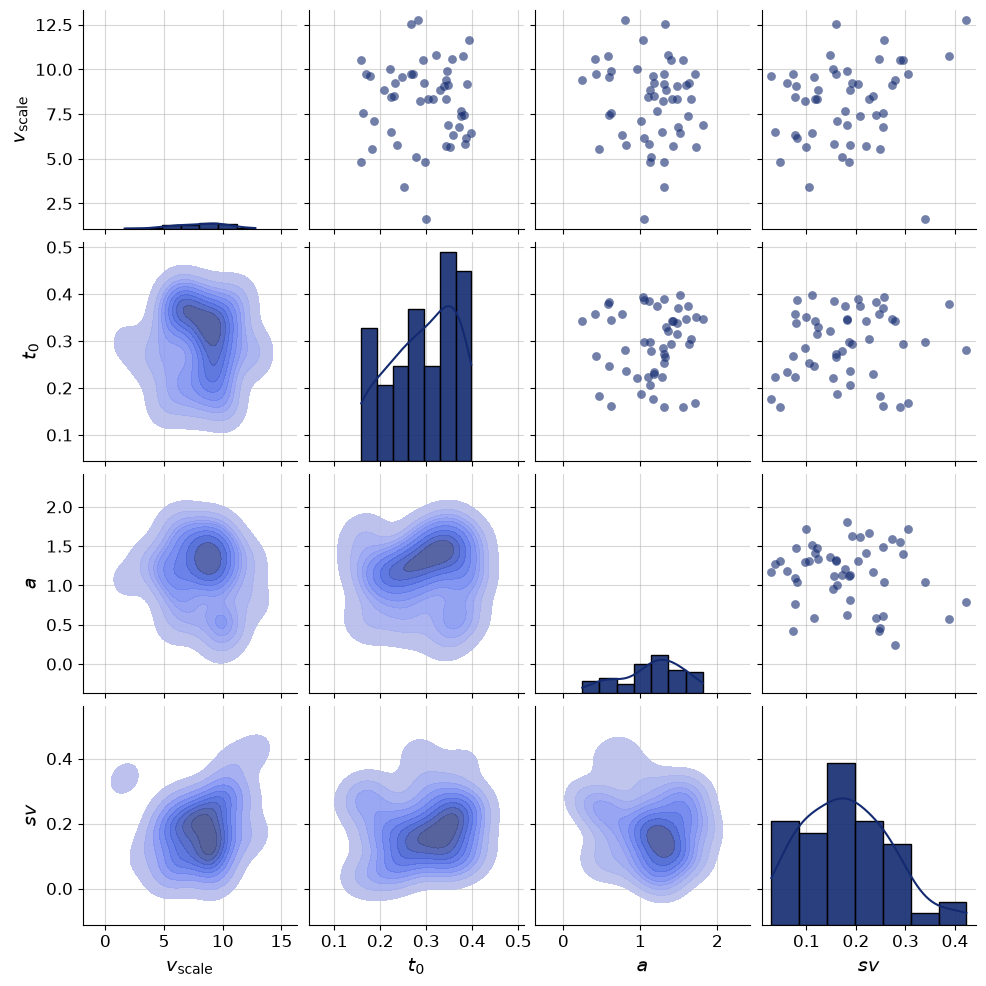

In [18]:
f = bf.diagnostics.plots.pairs_samples(
    samples=sim_draws,
    variable_keys=par_keys,
    variable_names=par_names
)

In [40]:
# 4 Parameter: v_scale, t0, a, lam
num_params = 4

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [57]:
import tensorflow as tf # Import tensorflow for tf.stack
import keras

@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # If the required keys are not present, return data as is.
    # This handles cases where data is already processed or in inverse mode.
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # Stack rt, choice, and coherence along a new axis to create a 2D array
    # Each row will be a trial, and columns will be its features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # Create a new dictionary from the input data, keeping all original keys
    # and adding 'summary_variables'. Explicitly remove the original
    # 'rt', 'choice', 'coherence' as they are now combined.
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    # design variables known as conditions (no inference)
    .concatenate(["cue", "has_deadline"], into="inference_conditions")
    # target parameters to be estimated (only the 4 core parameters for inference network)
    .concatenate(["v_scale", "t0", "a", "sv"], into="inference_variables")
    # Use add_transform to stack rt, choice, coherence and name the output 'summary_variables'
    .add_transform(stack_trials_for_deepset)
    # Drop 'difficulty' and other parameters not needed for inference/summary networks
    .drop(["difficulty", "model_idx", "k", "lam", "k_sig", "t_mid"])
    .keep(["inference_conditions", "inference_variables", "summary_variables"])
)

In [ ]:
import os

CHECKPOINT_DIR = "checkpoints/ddm_sbi_run"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name="ddm_workflow",
)


In [22]:
sample = simulator.sample(batch_shape=(8,))

In [ ]:
history = workflow.fit_online(epochs=100, batch_size=32, num_batches_per_epoch=20)

# Save the loss history atomically (so a crash never leaves a corrupt/empty file)
import pickle, os

history_path = "bayesflow_history_100.pkl"
tmp_path = history_path + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(history, f)
os.replace(tmp_path, history_path)

print(f"History saved successfully to {history_path}!")
print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")


In [ ]:
# NOTE: the model weights are saved automatically via `checkpoint_filepath`
# above (Keras checkpoint), so no separate manual save is needed here anymore.
# The pickle file only ever contained the loss history, never the trained
# network - that mismatch was the cause of the earlier EOFError / untrained
# workflow issues.


In [ ]:
import pickle, os
import keras

history_path = "bayesflow_history_100.pkl"

if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )

# If you're continuing in a NEW session (kernel restarted after training),
# reload the actual trained weights here instead of relying on `workflow`,
# which would otherwise be an untrained, freshly-initialized object:
#
# approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, "ddm_workflow.keras"))
#
# and then sample from `approximator` instead of `workflow` below.


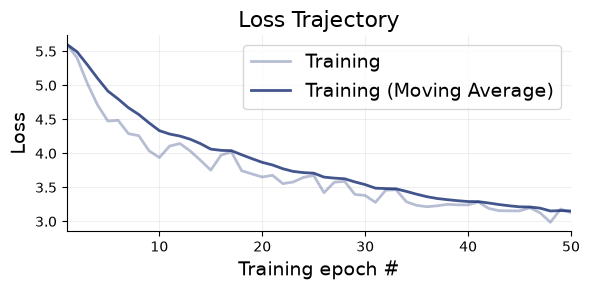

In [60]:
f  = bf.diagnostics.loss(history, figsize=(6,3))

In [ ]:
test_data = workflow.simulate(100)

# Pass the RAW simulated data straight to workflow.sample() - it applies the
# adapter internally. Applying `adapter(...)` manually beforehand (as before)
# caused a double-adaptation and the "strict=False before strict=True" error.
samples = workflow.sample(num_samples=1000, conditions=test_data)


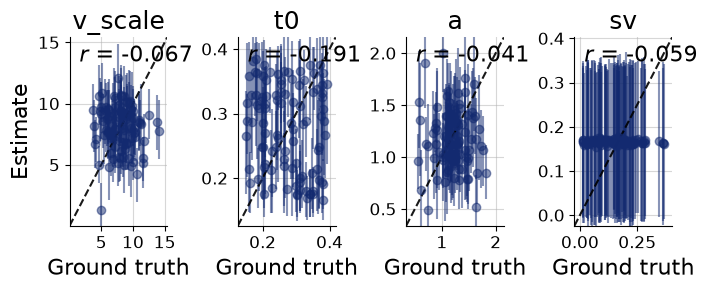

In [65]:
f2 = bf.diagnostics.recovery(samples, test_data, figsize=(7, 3))

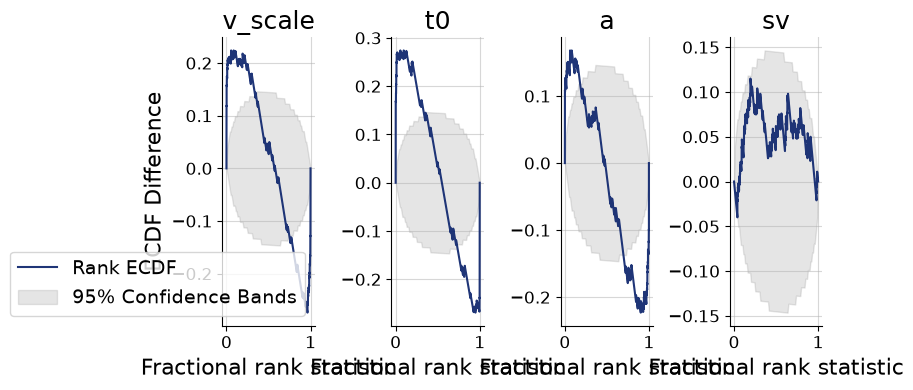

In [66]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_data, figsize=(8, 4))

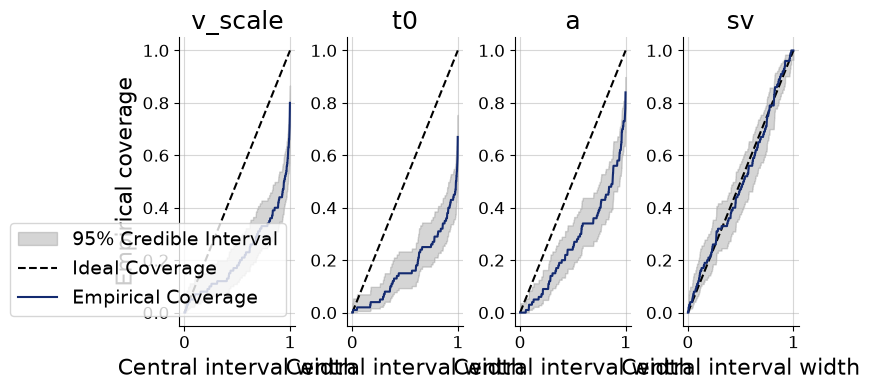

In [67]:
f4 = bf.diagnostics.coverage(samples, test_data, figsize=(8, 4))


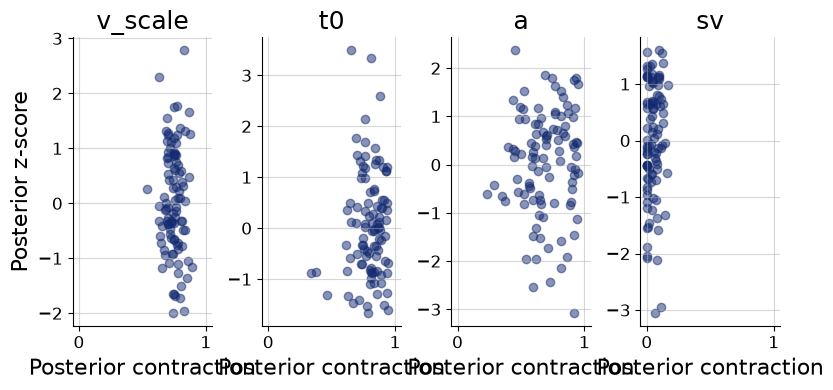

In [31]:
# Posterior contraction
f5 = bf.diagnostics.z_score_contraction(samples, test_data, figsize=(8, 4))
